# 📊 02 Analysis & Visualisation: UK Fuel Prices

**Goal:** answer the business questions with clear, colourful charts.

- 📈 **BQ1:** How have petrol and diesel prices changed over time?
- 🏷️ **BQ2:** Which brands are cheapest, and are supermarkets cheaper?
- 🛣️ **BQ3:** How much more do motorway stations charge?
- 🗺️ **BQ4:** Which cities pay the most and least?
- ⛽ **BQ5:** What is the gap between diesel and petrol?

## ⚖️ Ethics note (Analysis)

- 🚫 **Fair use of results:** rankings describe average prices, not blame on any brand, station or city
- 📏 **Small samples:** brands with fewer than 30 stations and cities with fewer than 20 are excluded from rankings
- 🌍 **Social context:** prices differ by area for reasons such as rural costs and competition, which this data cannot explain
- 🗓️ **Limits:** only Feb to Oct 2026 is covered, so no seasonal conclusions are drawn
- 🧑‍🤝‍🧑 **Plain language:** results are explained simply so non-technical readers are not misled

## 1️⃣ Import libraries and set a colourful style

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# One colour per fuel, used in every chart so it is easy to follow
COLOURS = {"Petrol": "#2A9D8F", "Diesel": "#E76F51"}
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (11, 5)

## 2️⃣ Load the cleaned data (version 1)

In [2]:
prices = pd.read_csv("../data/cleaned/v1/prices_cleaned.csv", parse_dates=["recorded_at"])
stations = pd.read_csv("../data/cleaned/v1/stations_cleaned.csv")

# Join prices to station details
df = prices.merge(stations[["node_id", "brand_name", "city", "station_type"]], on="node_id")
print("Rows:", df.shape[0])
print("Dates:", df["recorded_at"].min().date(), "to", df["recorded_at"].max().date())

Rows: 1180846
Dates: 2026-02-07 to 2026-10-21


In [3]:
# For fair comparisons we use the two most common fuels:
#   E10 = standard petrol, B7_STANDARD = standard diesel
std = df[df["fuel_type"].isin(["E10", "B7_STANDARD"])].copy()

# Average price PER STATION first, so busy stations do not count more than quiet ones
station_avg = (std.groupby(["node_id", "fuel_type", "brand_name", "city", "station_type"], as_index=False)
                  ["price_pence"].mean())
station_avg.head()

,node_id,fuel_type,brand_name,city,station_type,price_pence
0,00008759c79a869b9f324a75570897e003020b74a97383...,B7_STANDARD,Tesco,Harrogate,Other,170.965625
1,00008759c79a869b9f324a75570897e003020b74a97383...,E10,Tesco,Harrogate,Other,151.529167
2,0001347cef1b054562d9934ab25c6e87de6e2597ca7ccf...,B7_STANDARD,Murco,Carmarthenshire,Supermarket,182.983333
3,0001347cef1b054562d9934ab25c6e87de6e2597ca7ccf...,E10,Murco,Carmarthenshire,Supermarket,156.400000
4,000814b62c57b8e59a11dd760a6cf98ea34075c7c19c05...,B7_STANDARD,Gulf,Totland Bay,Other,188.923077


## 📈 BQ1: Price over time

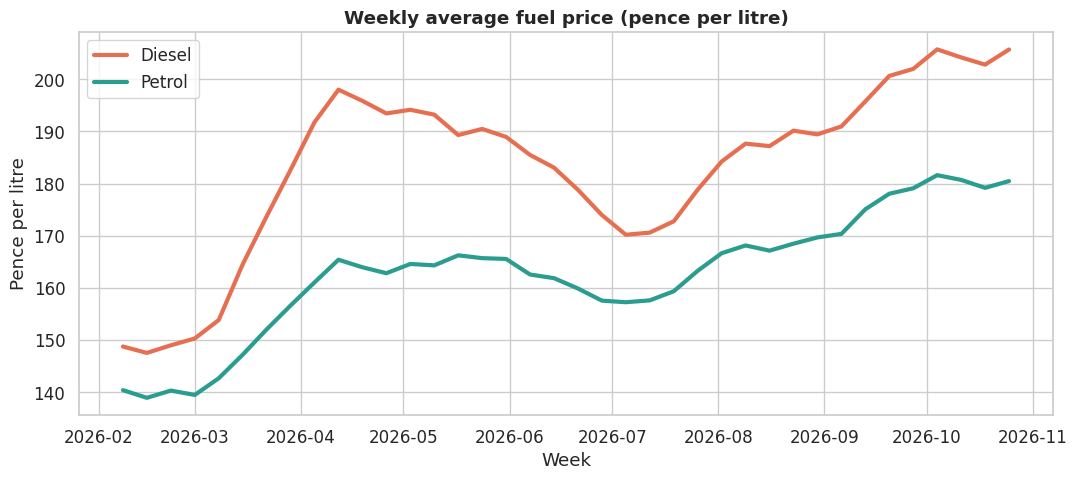

First week: {'Diesel': 148.8, 'Petrol': 140.4}
Last week:  {'Diesel': 205.7, 'Petrol': 180.5}
Peak week:
fuel_group recorded_at  price_pence
    Diesel  2026-10-04        205.7
    Petrol  2026-10-04        181.6


In [4]:
# Weekly average price for Petrol and Diesel
weekly = (df[df["fuel_group"].isin(["Petrol", "Diesel"])]
          .set_index("recorded_at").groupby("fuel_group")["price_pence"]
          .resample("W").mean().reset_index())

fig, ax = plt.subplots()
sns.lineplot(data=weekly, x="recorded_at", y="price_pence", hue="fuel_group",
             palette=COLOURS, linewidth=3, ax=ax)
ax.set_title("Weekly average fuel price (pence per litre)", fontweight="bold")
ax.set_xlabel("Week"); ax.set_ylabel("Pence per litre"); ax.legend(title="")
plt.tight_layout(); plt.savefig("../images/bq1_price_over_time.png", dpi=150); plt.show()

first, last = weekly.groupby("fuel_group")["price_pence"].first(), weekly.groupby("fuel_group")["price_pence"].last()
print("First week:", first.round(1).to_dict())
print("Last week: ", last.round(1).to_dict())
peak = weekly.loc[weekly.groupby("fuel_group")["price_pence"].idxmax()].copy()
peak["price_pence"] = peak["price_pence"].round(1)
print("Peak week:"); print(peak[["fuel_group", "recorded_at", "price_pence"]].to_string(index=False))

**📌 Result**
- ⬆️ Petrol rose from **140.4p to 180.5p** (+29%) and diesel from **148.8p to 205.7p** (+38%) between February and October 2026
- 🔝 Both fuels peaked in the week ending 4 October, and prices are still close to that peak
- 💡 Diesel rose faster than petrol

## 🏷️ BQ2: Brands and supermarkets

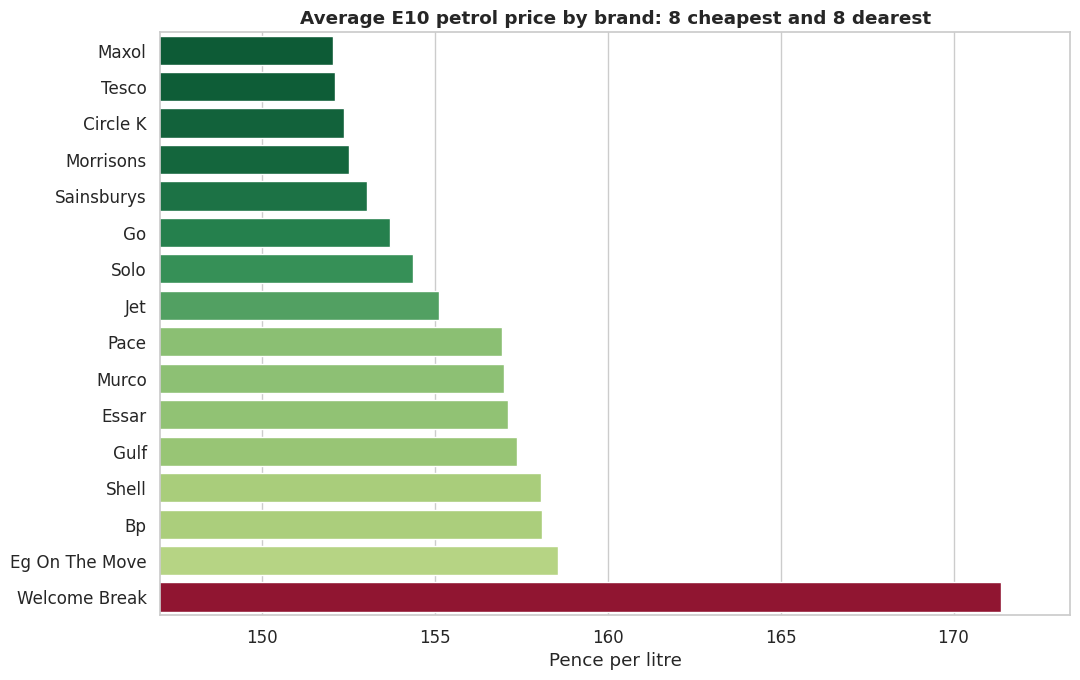

    brand_name   avg  stations
         Maxol 152.0        94
         Tesco 152.1       516
      Circle K 152.4        46
     Morrisons 152.5       340
    Sainsburys 153.0       316
            Go 153.7        30
          Solo 154.4        41
           Jet 155.1       309
          Pace 156.9        47
         Murco 157.0       163
         Essar 157.1        34
          Gulf 157.4       288
         Shell 158.1       871
            Bp 158.1      1041
Eg On The Move 158.6       147
 Welcome Break 171.4        40


In [5]:
# Only brands with at least 30 stations, so averages are reliable
e10 = station_avg[station_avg["fuel_type"] == "E10"]
brand = e10.groupby("brand_name")["price_pence"].agg(avg="mean", stations="count").reset_index()
brand = brand[brand["stations"] >= 30].sort_values("avg")

# Show the 8 cheapest and 8 dearest together
show = pd.concat([brand.head(8), brand.tail(8)])
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=show, x="avg", y="brand_name", hue="avg", palette="RdYlGn_r", legend=False, ax=ax)
ax.set_xlim(show["avg"].min() - 5, show["avg"].max() + 2)
ax.set_title("Average E10 petrol price by brand: 8 cheapest and 8 dearest", fontweight="bold")
ax.set_xlabel("Pence per litre"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("../images/bq2_brands.png", dpi=150); plt.show()

print(show.round(1).to_string(index=False))

In [6]:
# Supermarkets vs the rest
type_avg = (station_avg.groupby(["station_type", "fuel_type"])["price_pence"].mean().round(1).unstack())
type_avg

fuel_type,B7_STANDARD,E10
station_type,,
Motorway,192.5,174.0
Other,178.1,156.6
Supermarket,175.0,153.9


**📌 Result**
- 💚 Cheapest petrol (E10): Maxol (152.0p), Tesco (152.1p), Circle K (152.4p), Morrisons (152.5p), Sainsbury's (153.0p)
- 🔴 Dearest: Welcome Break (171.4p), then EG On The Move, BP and Shell (about 158p)
- 🛒 Supermarkets are about **2.7p cheaper** for petrol and **3.1p cheaper** for diesel than other stations

## 🛣️ BQ3: Motorway stations

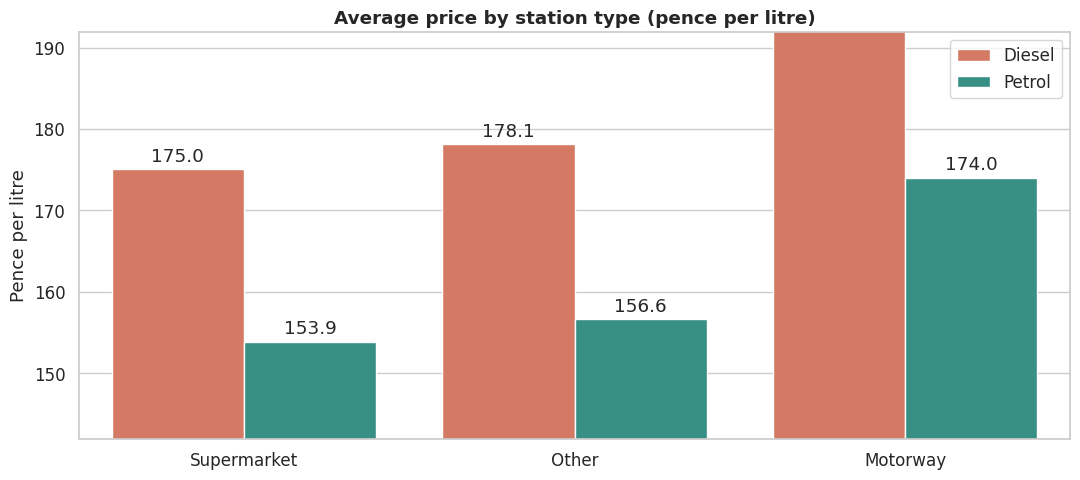

Motorway vs Other (pence more per litre): {'B7_STANDARD': 14.4, 'E10': 17.4}


In [7]:
plot = station_avg.copy()
plot["fuel"] = plot["fuel_type"].map({"E10": "Petrol", "B7_STANDARD": "Diesel"})
order = ["Supermarket", "Other", "Motorway"]

fig, ax = plt.subplots()
sns.barplot(data=plot, x="station_type", y="price_pence", hue="fuel", order=order,
            palette=COLOURS, errorbar=None, ax=ax)
ax.set_ylim(plot["price_pence"].mean() - 25, plot["price_pence"].mean() + 25)
for c in ax.containers: ax.bar_label(c, fmt="%.1f", padding=3)
ax.set_title("Average price by station type (pence per litre)", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("Pence per litre"); ax.legend(title="")
plt.tight_layout(); plt.savefig("../images/bq3_station_type.png", dpi=150); plt.show()

m = type_avg.loc["Motorway"] - type_avg.loc["Other"]
print("Motorway vs Other (pence more per litre):", m.round(1).to_dict())

**📌 Result**
- 🛣️ Motorway stations charge about **17.4p more** per litre for petrol and **14.4p more** for diesel than ordinary stations
- 💡 Filling up before joining a motorway is the simplest saving for drivers

## 🗺️ BQ4: Cities

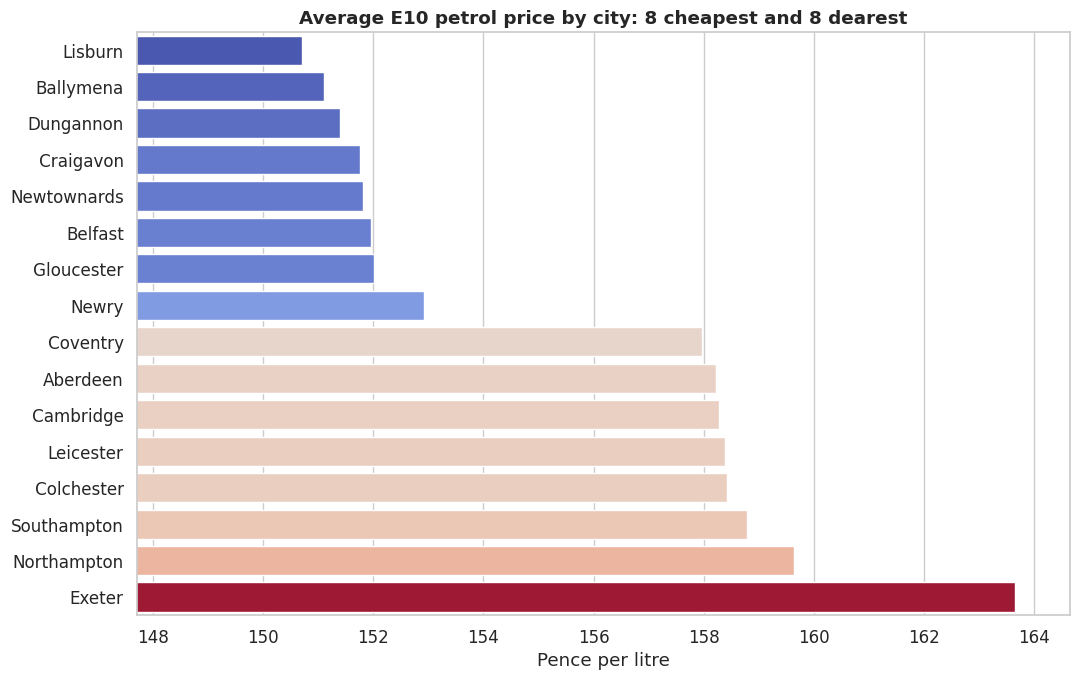

       city   avg  stations
    Lisburn 150.7        20
  Ballymena 151.1        22
  Dungannon 151.4        25
  Craigavon 151.8        27
Newtownards 151.8        20
    Belfast 152.0        64
 Gloucester 152.0        28
      Newry 152.9        22
   Coventry 158.0        33
   Aberdeen 158.2        23
  Cambridge 158.3        24
  Leicester 158.4        44
 Colchester 158.4        24
Southampton 158.8        34
Northampton 159.6        34
     Exeter 163.7        20
Cities compared: 51


In [8]:
# Only cities with at least 20 stations
city = e10[e10["city"] != "Unknown"].groupby("city")["price_pence"].agg(avg="mean", stations="count").reset_index()
city = city[city["stations"] >= 20].sort_values("avg")
show = pd.concat([city.head(8), city.tail(8)])

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=show, x="avg", y="city", hue="avg", palette="coolwarm", legend=False, ax=ax)
ax.set_xlim(show["avg"].min() - 3, show["avg"].max() + 1)
ax.set_title("Average E10 petrol price by city: 8 cheapest and 8 dearest", fontweight="bold")
ax.set_xlabel("Pence per litre"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("../images/bq4_cities.png", dpi=150); plt.show()

print(show.round(1).to_string(index=False))
print("Cities compared:", len(city))

**📌 Result**
- 💚 Cheapest petrol: Lisburn (150.7p), Ballymena (151.1p), Dungannon (151.4p). Seven of the eight cheapest cities are in Northern Ireland
- 🔴 Dearest: Exeter (163.7p), Northampton (159.6p), Southampton (158.8p)
- 📏 The gap between cheapest and dearest of the 51 cities compared (20+ stations each) is about **13p per litre**

## ⛽ BQ5: Diesel vs petrol gap

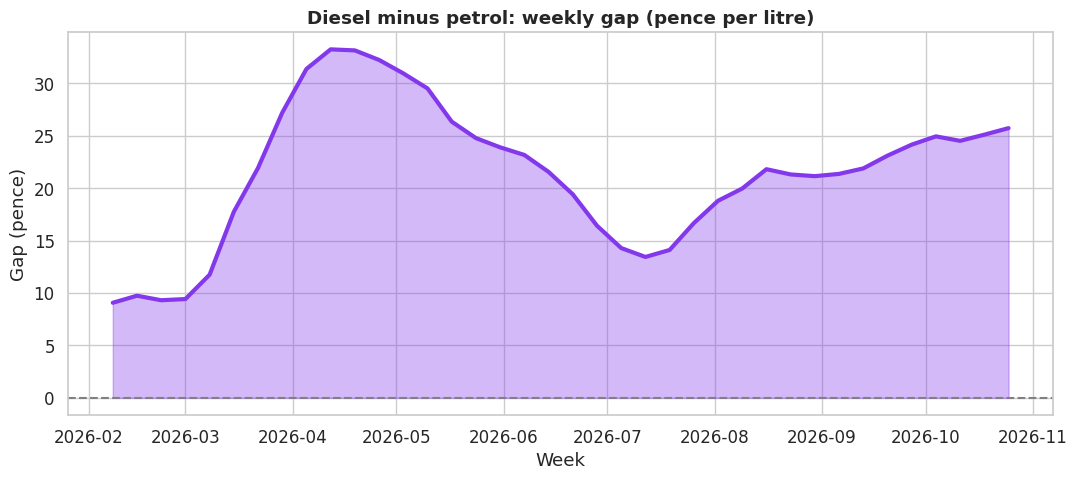

Weeks with diesel dearer than petrol: 38 of 38
Gap first week: 9.1 | last week: 25.7 | average: 21.4


In [9]:
# Gap = standard diesel minus standard petrol, per week
w = (std.set_index("recorded_at").groupby("fuel_type")["price_pence"].resample("W").mean().unstack(0))
w["gap"] = w["B7_STANDARD"] - w["E10"]
w = w.reset_index()

fig, ax = plt.subplots()
ax.fill_between(w["recorded_at"], w["gap"], 0, color="#8338EC", alpha=0.35)
ax.plot(w["recorded_at"], w["gap"], color="#8338EC", linewidth=3)
ax.axhline(0, color="grey", linestyle="--")
ax.set_title("Diesel minus petrol: weekly gap (pence per litre)", fontweight="bold")
ax.set_xlabel("Week"); ax.set_ylabel("Gap (pence)")
plt.tight_layout(); plt.savefig("../images/bq5_diesel_petrol_gap.png", dpi=150); plt.show()

print("Weeks with diesel dearer than petrol:", int((w["gap"] > 0).sum()), "of", len(w))
print("Gap first week:", round(w["gap"].iloc[0], 1), "| last week:", round(w["gap"].iloc[-1], 1), "| average:", round(w["gap"].mean(), 1))

**📌 Result**
- ⛽ Diesel was dearer than petrol in **all 38 weeks**
- 📈 The gap grew from **9.1p** in the first week to **25.7p** in the latest week (average 21.4p)

## ✅ Conclusions
- 📈 **BQ1:** Prices rose strongly in 2026 and are near their peak
- 🏷️ **BQ2:** Supermarkets and brands like Maxol are cheapest
- 🛣️ **BQ3:** Motorway stations carry a large premium
- 🗺️ **BQ4:** Prices vary by city, with Northern Ireland cheapest
- ⛽ **BQ5:** Diesel is always dearer than petrol, and the gap is widening

**💼 Recommendations**
- Drivers: use supermarket stations and avoid motorway stops
- Fleets: diesel costs are rising faster, so budget for this

**⚠️ Limitations**
- Data covers February to October 2026 only, so seasonal patterns cannot be tested
- Averages use all recorded prices, and some cities have few stations
- No personal data is used (see README ethics section)